HOUSE RENT (MULTIPLE LINEAR REGRESSION) part 1.0v(selected features)

Data extraction , EDA and Data Processing

In [17]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

In [18]:
whole=pd.read_csv("House_Rent_Dataset.csv")

In [19]:
whole.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4746 entries, 0 to 4745
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Posted On          4746 non-null   object
 1   BHK                4746 non-null   int64 
 2   Rent               4746 non-null   int64 
 3   Size               4746 non-null   int64 
 4   Floor              4746 non-null   object
 5   Area Type          4746 non-null   object
 6   Area Locality      4746 non-null   object
 7   City               4746 non-null   object
 8   Furnishing Status  4746 non-null   object
 9   Tenant Preferred   4746 non-null   object
 10  Bathroom           4746 non-null   int64 
 11  Point of Contact   4746 non-null   object
dtypes: int64(4), object(8)
memory usage: 445.1+ KB


In [20]:
whole["Rent_per_sqft"] = whole["Rent"] / whole["Size"]
whole.groupby("City")["Rent_per_sqft"].agg(
    ["count", "mean", "median", "std"]
)

,count,mean,median,std
City,,,,
Bangalore,886,21.751740,17.500000,47.911811
Chennai,891,19.785751,16.216216,23.885343
Delhi,605,67.631495,28.571429,90.467248
Hyderabad,868,23.585529,14.545455,70.550080
Kolkata,524,16.491473,13.315603,19.565843
Mumbai,972,81.668894,71.428571,41.495356


<Axes: xlabel='Rent_per_sqft'>

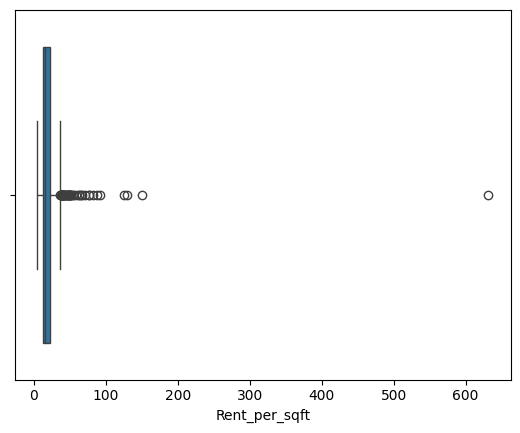

In [21]:
sns.boxplot(x=whole[(whole["City"]=="Chennai") ]["Rent_per_sqft"])


Text(0.5, 1.0, 'Bangalore')

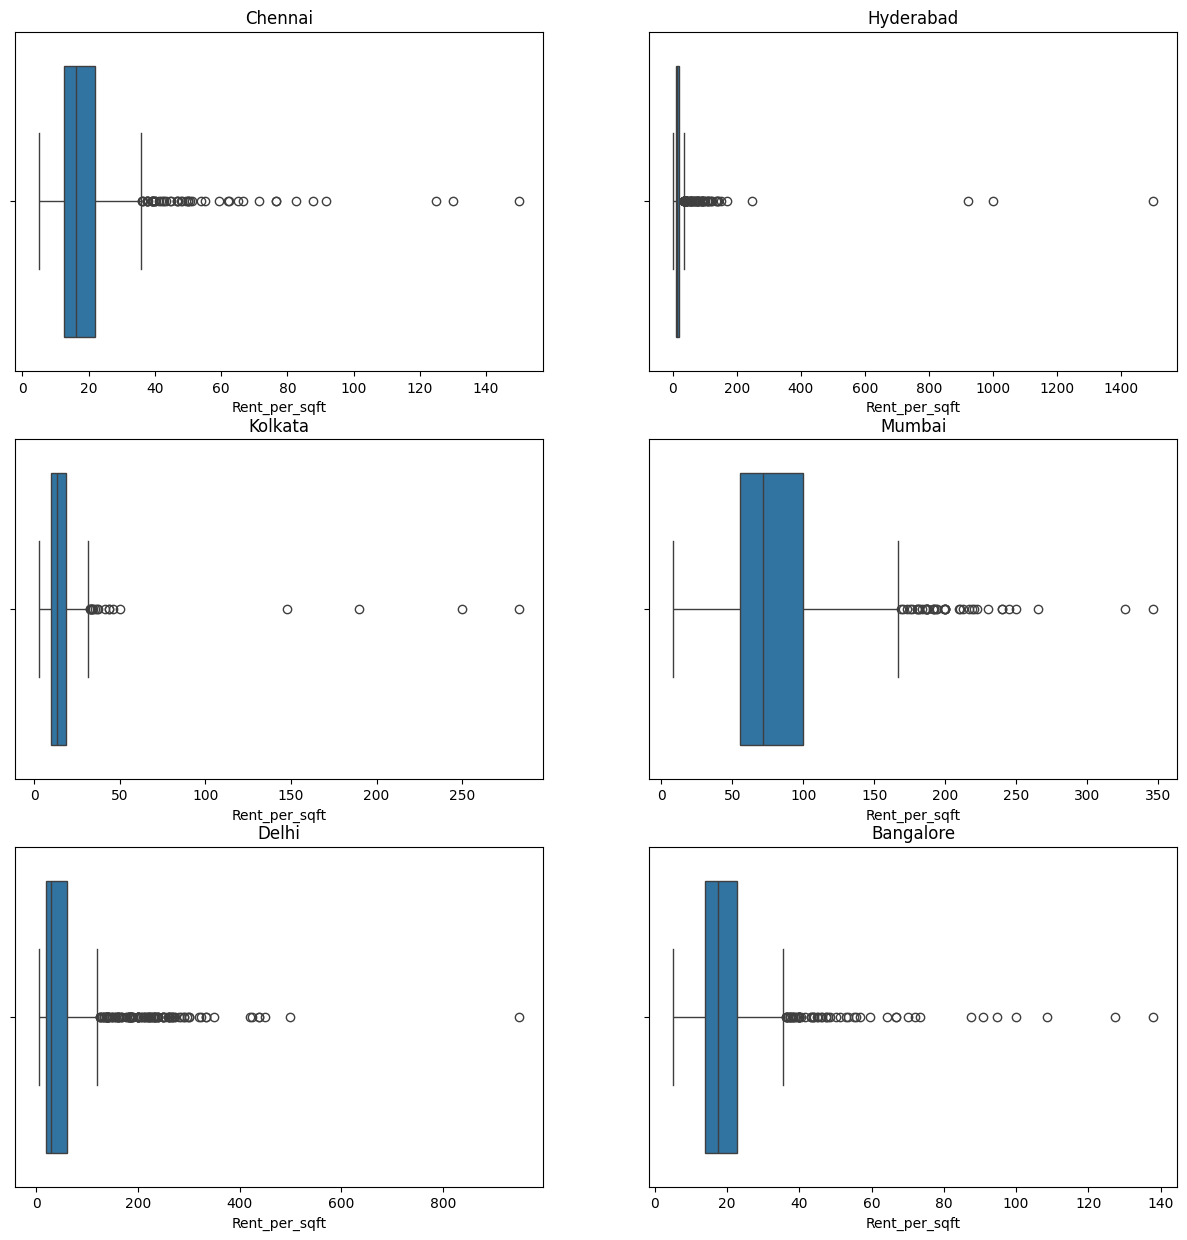

In [23]:
fig ,axes=plt.subplots(3,2,figsize=(15,15))

sns.boxplot(x=whole[(whole["City"]=="Chennai") & (whole["Rent_per_sqft"]<600)]["Rent_per_sqft"] ,ax=axes[0,0])
axes[0,0].set_title("Chennai")
sns.boxplot(x=whole[whole["City"]=="Hyderabad"]["Rent_per_sqft"] ,ax=axes[0,1])
axes[0,1].set_title("Hyderabad")
sns.boxplot(x=whole[whole["City"]=="Kolkata"]["Rent_per_sqft"] ,ax=axes[1,0])
axes[1,0].set_title("Kolkata")
sns.boxplot(x=whole[whole["City"]=="Mumbai"]["Rent_per_sqft"] ,ax=axes[1,1])
axes[1,1].set_title("Mumbai")
sns.boxplot(x=whole[whole["City"]=="Delhi"]["Rent_per_sqft"] ,ax=axes[2,0])
axes[2,0].set_title("Delhi")
sns.boxplot(x=whole[(whole["City"]=="Bangalore") & (whole["Rent_per_sqft"]<1200) ]["Rent_per_sqft"] ,ax=axes[2,1])
axes[2,1].set_title("Bangalore")

In [24]:
whole[(whole["City"]=="Chennai") & (whole["Rent_per_sqft"]>600)]

,Posted On,BHK,Rent,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact,Rent_per_sqft
3656,2022-07-06,2,600000,950,1 out of 1,Carpet Area,Vettuvankeni,Chennai,Unfurnished,Bachelors,2,Contact Owner,631.578947


In [25]:
whole.iloc[3656]


Posted On               2022-07-06
BHK                              2
Rent                        600000
Size                           950
Floor                   1 out of 1
Area Type              Carpet Area
Area Locality         Vettuvankeni
City                       Chennai
Furnishing Status      Unfurnished
Tenant Preferred         Bachelors
Bathroom                         2
Point of Contact     Contact Owner
Rent_per_sqft           631.578947
Name: 3656, dtype: object

In [26]:
whole.drop(index=3656,inplace=True) #already

<Axes: xlabel='Rent_per_sqft'>

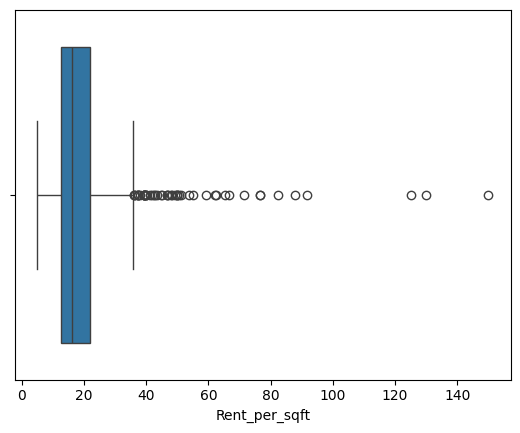

In [27]:
sns.boxplot(x=whole[(whole["City"]=="Chennai") ]["Rent_per_sqft"])

In [28]:
whole_chennai=whole[whole["City"]=="Chennai"]

In [29]:
whole_chennai

,Posted On,BHK,Rent,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact,Rent_per_sqft
2987,2022-07-06,2,15000,1100,1 out of 2,Super Area,Medavakkam,Chennai,Semi-Furnished,Bachelors,2,Contact Owner,13.636364
2988,2022-05-21,2,6500,1000,Ground out of 1,Super Area,"Urapakkam, Vandalur R.F, GST Road",Chennai,Semi-Furnished,Bachelors/Family,2,Contact Owner,6.500000
2989,2022-05-20,3,90000,2400,1 out of 3,Carpet Area,"R.A Puram, Mandaiveli",Chennai,Semi-Furnished,Bachelors/Family,3,Contact Agent,37.500000
2990,2022-07-10,3,200000,3000,1 out of 1,Super Area,Madras Boat Club Road,Chennai,Furnished,Family,4,Contact Agent,66.666667
2991,2022-06-25,1,15000,650,Ground out of 2,Carpet Area,Kambar Colony,Chennai,Semi-Furnished,Bachelors/Family,1,Contact Owner,23.076923
...,...,...,...,...,...,...,...,...,...,...,...,...,...
3873,2022-07-10,3,28000,1050,5 out of 10,Carpet Area,Pallavaram,Chennai,Semi-Furnished,Bachelors/Family,3,Contact Agent,26.666667
3874,2022-06-22,2,10677,800,5 out of 6,Super Area,"Kelambakkam, Old Mahabalipuram Road",Chennai,Semi-Furnished,Bachelors/Family,2,Contact Owner,13.346250
3875,2022-07-01,3,50000,1625,8 out of 11,Super Area,Old Mahabalipuram Road,Chennai,Furnished,Bachelors/Family,3,Contact Agent,30.769231
3876,2022-06-17,3,32500,1535,1 out of 2,Super Area,Karapakkam,Chennai,Unfurnished,Bachelors/Family,3,Contact Agent,21.172638


feature extraction

In [30]:
df=whole_chennai.copy()

In [13]:
#not now
cats = ["Area Type", "Tenant Preferred", "Point of Contact"]   # columns to convert
features=["BHK","Size","Floor","Furnishing Status","Bathroom","Rent"]
whole_chennai = whole_chennai.copy()
whole_chennai["Area Type"] = whole_chennai["Area Type"].replace("Built Area", "Super Area")  # merge the 1-row category

X_new = pd.get_dummies(
    whole_chennai[features + cats],   # your 6 numeric columns + the 3 text columns
    columns=cats,            # only encode these 3; numeric columns pass through unchanged
    drop_first=True,         # drop one column per category (the reference)
    dtype=float              # 0.0/1.0 instead of True/False
)
print(X_new.columns.tolist())
df=X_new.copy()

['BHK', 'Size', 'Floor', 'Furnishing Status', 'Bathroom', 'Rent', 'Area Type_Super Area', 'Tenant Preferred_Bachelors/Family', 'Tenant Preferred_Family', 'Point of Contact_Contact Owner']


In [31]:
df = df.sample(frac=1, random_state=42)

In [32]:
df["Furnishing Status"] = df["Furnishing Status"].map({"Unfurnished": 0, "Semi-Furnished": 1, "Furnished": 2})
df.head()

,Posted On,BHK,Rent,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact,Rent_per_sqft
3267,2022-05-30,2,17500,650,2 out of 2,Carpet Area,Thiruvanmiyur,Chennai,2,Bachelors/Family,2,Contact Owner,26.923077
3421,2022-06-23,3,30000,1300,19 out of 19,Super Area,Navalur,Chennai,2,Bachelors/Family,3,Contact Owner,23.076923
3026,2022-05-21,2,12000,850,Ground out of 2,Super Area,Perambur,Chennai,0,Family,2,Contact Owner,14.117647
3404,2022-05-06,1,18000,500,1 out of 4,Super Area,"George Town, PH Road",Chennai,0,Bachelors/Family,1,Contact Owner,36.000000
3572,2022-05-25,2,18000,1000,1 out of 2,Super Area,Sholinganallur,Chennai,0,Bachelors/Family,2,Contact Owner,18.000000


In [33]:
df['Total_Floors']=df["Floor"].str.extract(r"out of\s*(\d+)")[0].astype(float)

In [34]:
df['Floor_no.']=df["Floor"].str.extract(r"^(\d+)")

In [35]:
df["Floor_no."].value_counts()

Floor_no.
1     321
2     164
3      59
4      30
9      13
5      11
7      10
8       7
10      6
15      6
11      6
6       5
12      3
17      2
19      2
20      1
16      1
25      1
13      1
24      1
28      1
14      1
Name: count, dtype: int64

In [36]:
df.loc[df["Floor"].str.startswith("Ground", na=False),"Floor_no."] = 0

df.loc[df["Floor"].str.startswith("Upper Basement", na=False),"Floor_no."] = -1

df.loc[df["Floor"].str.startswith("Lower Basement", na=False),"Floor_no."] = -2

In [37]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 890 entries, 3267 to 3089
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Posted On          890 non-null    object 
 1   BHK                890 non-null    int64  
 2   Rent               890 non-null    int64  
 3   Size               890 non-null    int64  
 4   Floor              890 non-null    object 
 5   Area Type          890 non-null    object 
 6   Area Locality      890 non-null    object 
 7   City               890 non-null    object 
 8   Furnishing Status  890 non-null    int64  
 9   Tenant Preferred   890 non-null    object 
 10  Bathroom           890 non-null    int64  
 11  Point of Contact   890 non-null    object 
 12  Rent_per_sqft      890 non-null    float64
 13  Total_Floors       890 non-null    float64
 14  Floor_no.          890 non-null    object 
dtypes: float64(2), int64(5), object(8)
memory usage: 111.2+ KB


In [38]:
df["Floor_no."] = df["Floor_no."].astype(float)

In [39]:
df.drop(columns=["Floor"],inplace=True)

In [40]:
df[df["Floor_no."]==-1].value_counts()

Posted On   BHK  Rent  Size  Area Type    Area Locality                            City     Furnishing Status  Tenant Preferred  Bathroom  Point of Contact  Rent_per_sqft  Total_Floors  Floor_no.
2022-06-14  1    8000  400   Carpet Area  Venkateshwara Nagar, Ramapuram, PH Road  Chennai  0                  Bachelors/Family  1         Contact Owner     20.0           2.0           -1.0         1
Name: count, dtype: int64

Feature selection for this model

In [41]:
df=df[['BHK','Size','Furnishing Status','Floor_no.','Total_Floors','Bathroom','Rent']]
df.head()

,BHK,Size,Furnishing Status,Floor_no.,Total_Floors,Bathroom,Rent
3267,2,650,2,2.0,2.0,2,17500
3421,3,1300,2,19.0,19.0,3,30000
3026,2,850,0,0.0,2.0,2,12000
3404,1,500,0,1.0,4.0,1,18000
3572,2,1000,0,1.0,2.0,2,18000


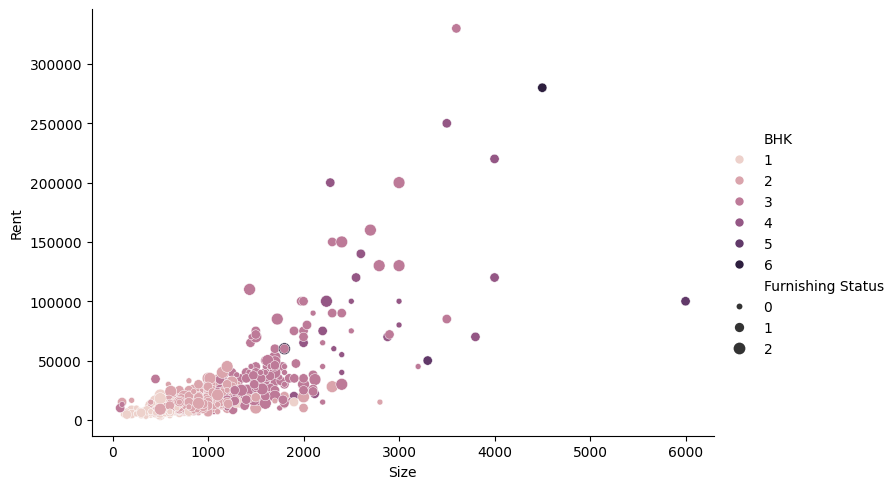

In [43]:
sns.relplot(kind="scatter",data=df,x='Size',y='Rent',hue='BHK',size='Furnishing Status',height=5,aspect=1.5)

<Axes: xlabel='BHK', ylabel='Rent'>

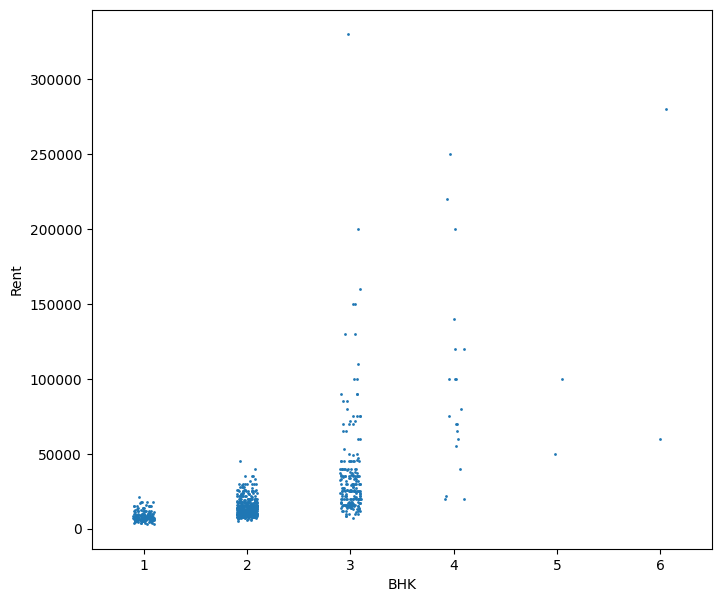

In [44]:
plt.figure(figsize=(8, 7))
sns.stripplot(data=df,x='BHK',y='Rent',size=2)

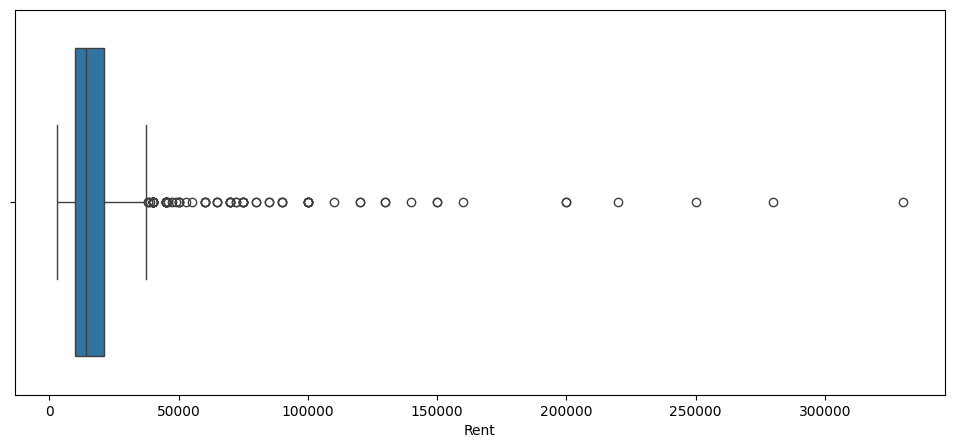

In [45]:
plt.figure(figsize=(12, 5))

sns.boxplot(x=df["Rent"])

plt.show()

<Axes: >

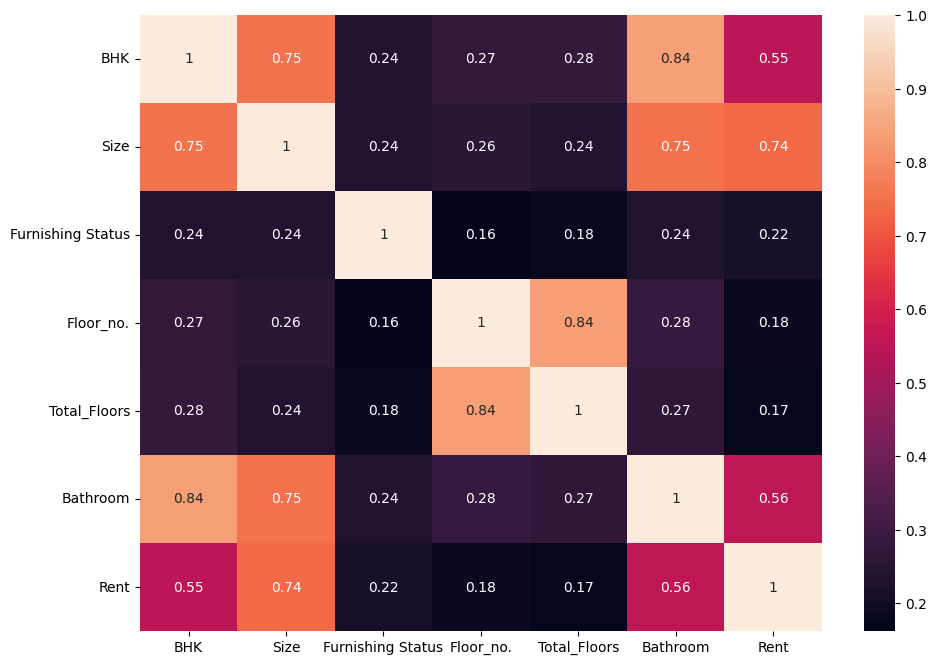

In [49]:
plt.figure(figsize=(11,8))
sns.heatmap(df.corr(numeric_only=True), annot=True)

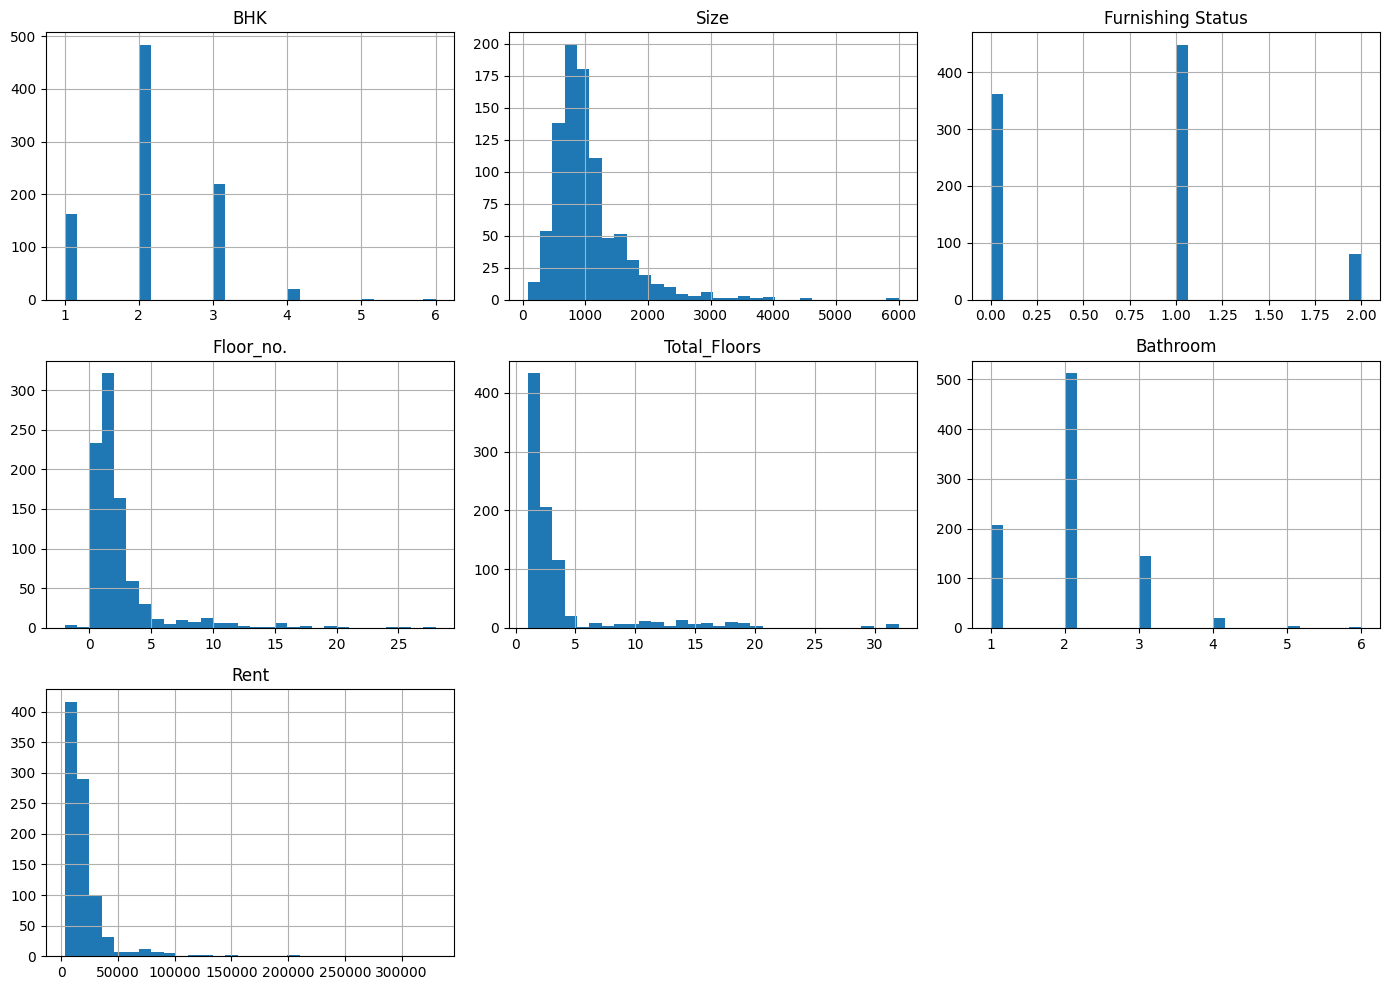

In [50]:
df.hist(figsize=(14, 10), bins=30)

plt.tight_layout()

plt.show()

In [51]:
df_c=df[df["Rent"]<100000]

In [52]:
# Find the split point

split = int(0.8 * len(df_c))

# Split

train_df = df_c.iloc[:split]

test_df = df_c.iloc[split:]

In [53]:

X_train, y_train = train_df .drop("Rent" ,axis=1), train_df["Rent"]
X_test,  y_test  = test_df.drop("Rent",axis=1), test_df["Rent"]


In [56]:


# ----------  Z-score scaling (stats from TRAIN only) ----------
mu = X_train.mean(axis=0)
sigma = X_train.std(axis=0)

X_train_s = (X_train - mu) / sigma
X_test_s = (X_test - mu) / sigma

# ----------  Gradient descent ----------
def gradient_descent(x, y, lr=0.03, epochs=1500):
    n_features = x.shape[1]
    w = np.zeros(n_features)
    b=0
    m = len(x)
    
    history = []
    for i in range(epochs):
        y_pred = np.dot(x,w) + b
        error = y_pred - y
        # Gradients
        dw = (1 / m) * np.dot(x.T, error)
        db = (1 / m) * np.sum(error)
        
        w -= lr * dw
        b -= lr * db
        history.append((1 / (2 * m)) * np.sum(error ** 2))   # cost
        if i % 200 == 0:
            print(f"epoch {i:4d}  cost = {history[-1]:.2f}")
    return w, b, history

w, b, cost_history = gradient_descent(X_train_s, y_train)
print(f"\nLearned weights (scaled space):")
print(w)
print(f"Bias (scaled space): {b:.2f}")

# Convert back to original units: y = w_orig * x + b_orig
w_orig = w / sigma
b_orig = b - np.sum(w * mu / sigma)
print("In original units:")
print("w =\n", w_orig)
print("b =", b_orig)

# ----------  Evaluation metrics ----------
def evaluate(y_true, y_pred):
    mse  = np.mean((y_true - y_pred) ** 2)
    rmse = np.sqrt(mse)
    mae  = np.mean(np.abs(y_true - y_pred))
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - y_true.mean()) ** 2)
    r2 = 1 - ss_res / ss_tot
    return mse, rmse, mae, r2

train_pred = np.dot(X_train_s, w) + b
test_pred  = np.dot(X_test_s, w) + b

for name, yt, yp in [("Train", y_train, train_pred), ("Test", y_test, test_pred)]:
    mse, rmse, mae, r2 = evaluate(yt, yp)
    print(f"{name}: MSE={mse:.1f}  RMSE={rmse:.1f}  MAE={mae:.1f}  R2={r2:.4f}")

epoch    0  cost = 251952082.66
epoch  200  cost = 39941174.27
epoch  400  cost = 39785174.81
epoch  600  cost = 39778618.31
epoch  800  cost = 39778318.45
epoch 1000  cost = 39778301.94
epoch 1200  cost = 39778300.72
epoch 1400  cost = 39778300.60

Learned weights (scaled space):
[1624.3936442  7755.39870932  867.77028241  264.10131978  671.19285987
  765.09741548]
Bias (scaled space): 17902.85
In original units:
w =
 BHK                  2252.411366
Size                   16.213989
Furnishing Status    1386.616404
Floor_no.              98.018478
Total_Floors          150.233601
Bathroom             1089.969840
dtype: float64
b = -6756.401950658339
Train: MSE=79556601.2  RMSE=8919.5  MAE=5921.0  R2=0.5662
Test: MSE=78737826.5  RMSE=8873.4  MAE=6046.6  R2=0.4937


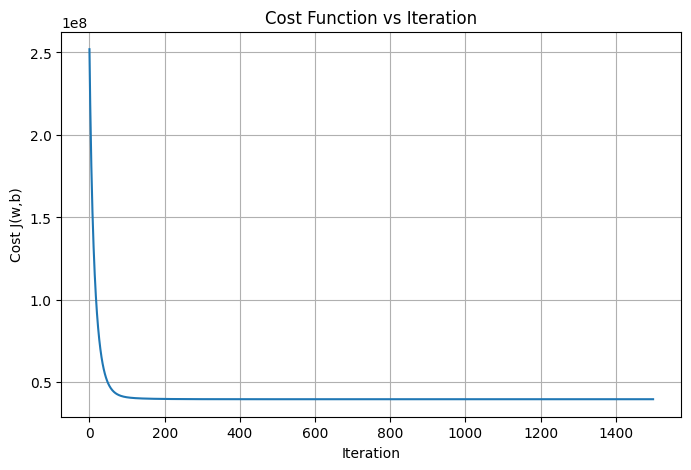

In [57]:
plt.figure(figsize=(8, 5))

plt.plot(cost_history)

plt.xlabel("Iteration")
plt.ylabel("Cost J(w,b)")
plt.title("Cost Function vs Iteration")

plt.grid(True)
plt.show()

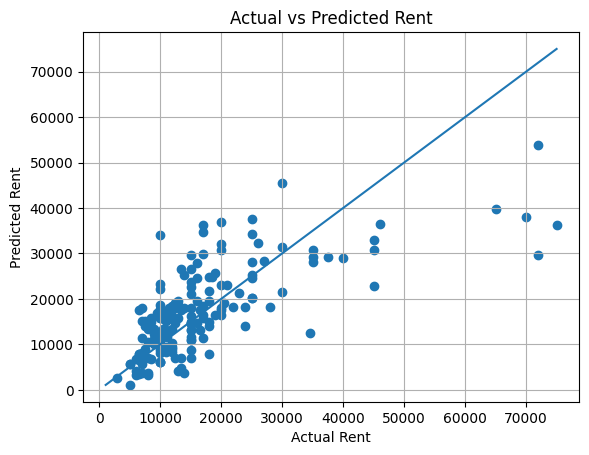

In [58]:
plt.scatter(y_test, test_pred)

minimum = min(y_test.min(), test_pred.min())
maximum = max(y_test.max(), test_pred.max())

plt.plot([minimum, maximum], [minimum, maximum])

plt.xlabel("Actual Rent")
plt.ylabel("Predicted Rent")
plt.title("Actual vs Predicted Rent")
plt.grid()
plt.show()

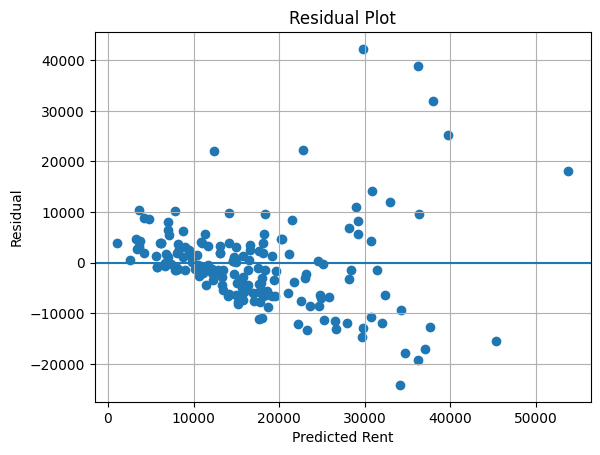

In [59]:
residuals = y_test - test_pred
plt.scatter(test_pred, residuals)

plt.axhline(0)

plt.xlabel("Predicted Rent")
plt.ylabel("Residual")
plt.title("Residual Plot")
plt.grid()
plt.show()